Энэ dataset нь 2011–2012 оны UCI Bike Sharing өгөгдөл бөгөөд Вашингтон, D.C. орчмын Capital Bikeshare системийн мэдээлэл юм. Тиймээс эцсийн assignment title болон poster дээрээ Dublin Bike Sharing гэж бичихгүй, өгөгдлийн бодит байршил, эх сурвалжийг зөв тусгаарай.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import os

os.environ["OMP_NUM_THREADS"] = "3"

In [5]:
# Load the Bike Sharing Dataset
df = pd.read_csv("day.csv")

# Display first 5 rows
df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In this section, I explored the Bike Sharing Dataset to understand the data before applying machine learning algorithms.

In [6]:
# Check dataset shape
print("Dataset shape:", df.shape)

# Check data types
df.info()

# Check missing values
print(df.isnull().sum())

# Check duplicate rows
print("Duplicates:", df.duplicated().sum())

# Statistical summary
df.describe()

Dataset shape: (731, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
instant       0
dteday        0
season        0
yr            0
mnth

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


The dataset contains **731 observations and 16 columns**. Moreover, I checked the dataset for missing values and found that there were **no missing values**.

## Exploratory Data Analysis (EDA)

In [7]:
# Convert date column to datetime format
df["dteday"] = pd.to_datetime(df["dteday"])

# Check the date range
print("Start Date:", df["dteday"].min())
print("End Date:", df["dteday"].max())

Start Date: 2011-01-01 00:00:00
End Date: 2012-12-31 00:00:00


The dataset is covering daily bike rental information **from 2011 to 2012**.

### 5.3 Daily Bike Rental Demand graphic

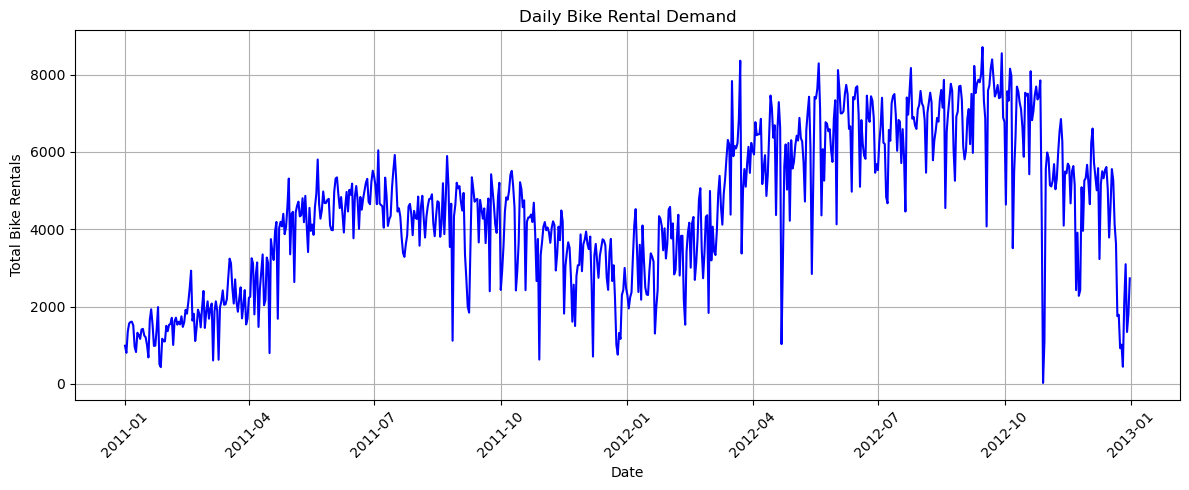

In [8]:
# Plot daily bike rental demand
plt.figure(figsize=(12, 5))

plt.plot(
    df["dteday"],
    df["cnt"],
    color="blue"
)

plt.title("Daily Bike Rental Demand")
plt.xlabel("Date")
plt.ylabel("Total Bike Rentals")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

### Interpretation: Daily Bike Rental Demand

The line graph shows the daily bike rental demand between 2011 and 2012.

Overall, bike rental demand increased during this period. The number of rentals was generally higher in 2012 compared to 2011.

The graph also shows seasonal patterns, with higher demand during warmer periods and lower demand during colder periods.

There are some sudden decreases in bike rentals, which may be related to weather conditions or other external factors.

This analysis suggests that time series forecasting could be useful for predicting future bike rental demand.

### 5.4 Average Bike Rentals by Season

season
1    2604.132597
2    4992.331522
3    5644.303191
4    4728.162921
Name: cnt, dtype: float64


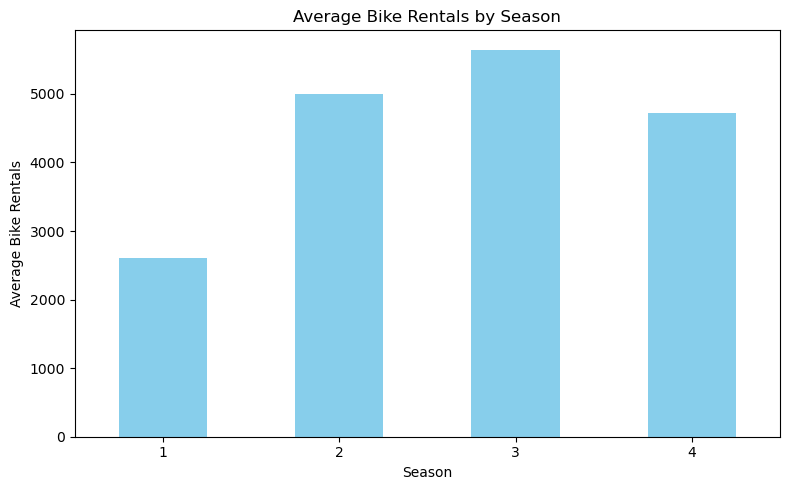

In [9]:
# Calculate average rentals by season
season_avg = df.groupby("season")["cnt"].mean()

print(season_avg)

# Plot seasonal demand
plt.figure(figsize=(8, 5))

season_avg.plot(
    kind="bar",
    color="skyblue"
)

plt.title("Average Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Average Bike Rentals")

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

### Interpretation: Average Bike Rentals by Season
The season code meaning is in UCI dataset 1 = Spring, 2 = Summer, 3 = Fall, 4 = Winter

The bar chart compares the average number of bike rentals across four seasons.

Autumn has the highest average demand, with approximately 5,644 rentals per day. Summer follows with around 4,992 rentals, while winter has approximately 4,728 rentals.

Spring has the lowest average demand, with approximately 2,604 rentals per day.

These results suggest that seasonality is an important factor influencing bike rental demand.

Understanding these seasonal differences could help bike-sharing companies improve resource allocation and operational planning.

### 5.5 Correlation Heatmap

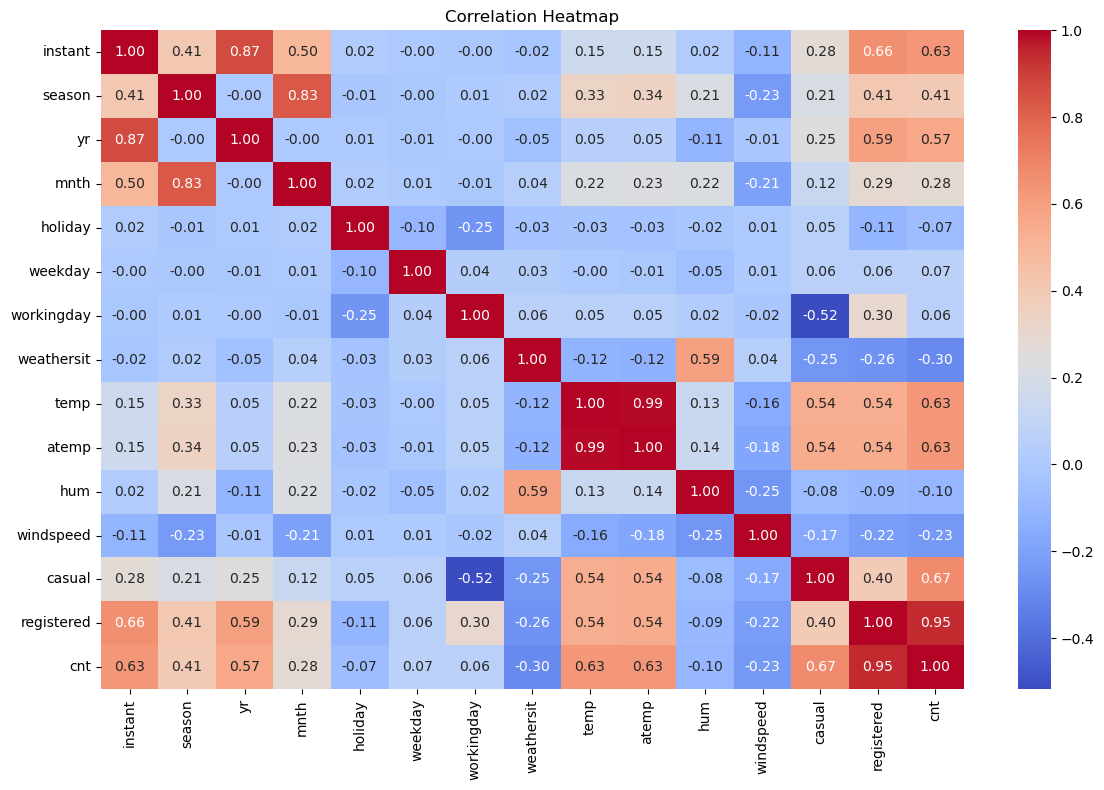

In [10]:
# Select numerical columns
numeric_df = df.select_dtypes(include=["number"])

# Calculate correlation
correlation = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

### Exploratory Data Analysis (EDA)

In this section, I used descriptive statistics and visualisations to investigate bike rental demand. These included a daily rental demand line graph, a seasonal demand bar chart, and a correlation heatmap.

The purpose of this analysis is to identify patterns and relationships in the data before applying clustering and time series forecasting models.

### Interpretation: Correlation Heatmap

The correlation heatmap shows the relationships between numerical variables in the Bike Sharing Dataset.

Temperature has a positive correlation of approximately 0.63 with total bike rentals. This suggests that bike rental demand tends to increase as temperature rises.

Weather conditions have a negative correlation of approximately -0.30 with total rentals, while windspeed has a correlation of approximately -0.23.

Registered and casual rentals are strongly correlated with total rentals because they are components of the total rental count.

Overall, the heatmap suggests that temperature and weather conditions are useful variables to investigate when analysing bike rental demand. However, correlation does not necessarily imply causation.

## 6. Clustering Analysis

### 6.1 Feature Selection and Data Scaling

In this section, I apply unsupervised machine learning algorithms to identify different patterns in bike rental demand.

I selected temperature, humidity, windspeed and total bike rentals as the main features for clustering.

These features represent weather conditions and bike rental activity. StandardScaler is used to standardise the selected variables so that differences in their numerical scales do not dominate the clustering results.

In [11]:
from sklearn.preprocessing import StandardScaler

# Select features for clustering
features = ["temp", "hum", "windspeed", "cnt"]

X = df[features].copy()

# Standardise the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original dataset shape:", X.shape)
print("Scaled dataset shape:", X_scaled.shape)

X.head()

Original dataset shape: (731, 4)
Scaled dataset shape: (731, 4)


,temp,hum,windspeed,cnt
0,0.344167,0.805833,0.160446,985
1,0.363478,0.696087,0.248539,801
2,0.196364,0.437273,0.248309,1349
3,0.200000,0.590435,0.160296,1562
4,0.226957,0.436957,0.186900,1600


### 6.2 Find the Best Number of Clusters

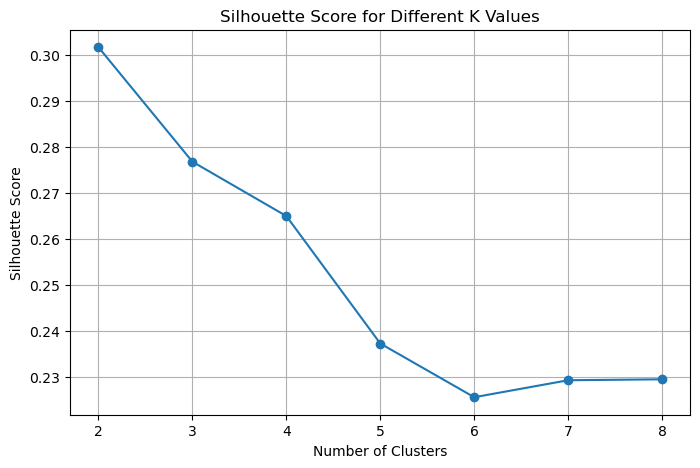

Best number of clusters: 2
Best Silhouette Score: 0.3016611538502967


In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 9)
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()

best_k = list(k_values)[np.argmax(silhouette_scores)]

print("Best number of clusters:", best_k)
print("Best Silhouette Score:", max(silhouette_scores))

### Interpretation: Optimal Number of Clusters

I used the Silhouette Score to find the most suitable number of clusters for the K-Means algorithm.

I tested cluster numbers from 2 to 8. The highest Silhouette Score was approximately 0.302 when the number of clusters was 2.

As the number of clusters increased, the Silhouette Score generally decreased.

Therefore, I selected two clusters for the K-Means model.

However, the score of 0.302 suggests that the clusters are only moderately separated, and some overlap may exist between the groups.

### 6.3 Apply K-Means Clustering

In [13]:
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("Cluster distribution:")
print(df["KMeans_Cluster"].value_counts().sort_index())

df[["dteday", "cnt", "KMeans_Cluster"]].head()

Cluster distribution:
KMeans_Cluster
0    313
1    418
Name: count, dtype: int64


,dteday,cnt,KMeans_Cluster
0,2011-01-01,985,0
1,2011-01-02,801,0
2,2011-01-03,1349,0
3,2011-01-04,1562,0
4,2011-01-05,1600,0


In [14]:
# Calculate average values for each cluster
cluster_profile = df.groupby("KMeans_Cluster")[
    ["temp", "hum", "windspeed", "cnt"]
].mean()

print("K-Means Cluster Profiles:")
display(cluster_profile.round(2))

K-Means Cluster Profiles:


,temp,hum,windspeed,cnt
KMeans_Cluster,,,,
0,0.33,0.59,0.22,2966.57
1,0.62,0.65,0.17,5655.84


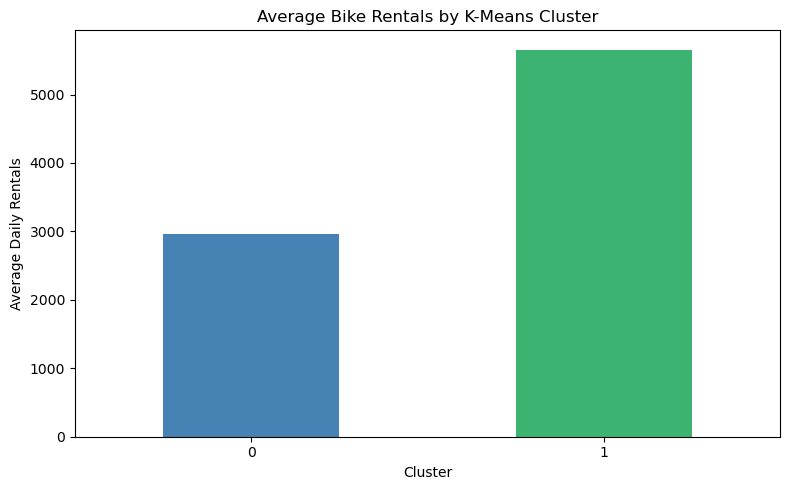

In [15]:
# Visualise average rentals by cluster
cluster_profile["cnt"].plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "mediumseagreen"]
)

plt.title("Average Bike Rentals by K-Means Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Daily Rentals")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretation: K-Means Clustering

The K-Means algorithm divided the dataset into two clusters.

Cluster 0 contains 313 observations, while Cluster 1 contains 418 observations.

The scatter plot shows that the two groups have different patterns of temperature and bike rental demand. Cluster 0 generally includes days with lower rental demand, while Cluster 1 contains many days with higher rental demand.

However, some observations overlap between the two clusters.

The results suggest that clustering can help identify different bike rental demand patterns. These patterns could support better planning and resource allocation for bike-sharing services.

### 6.4 Visualise K-Means Clusters

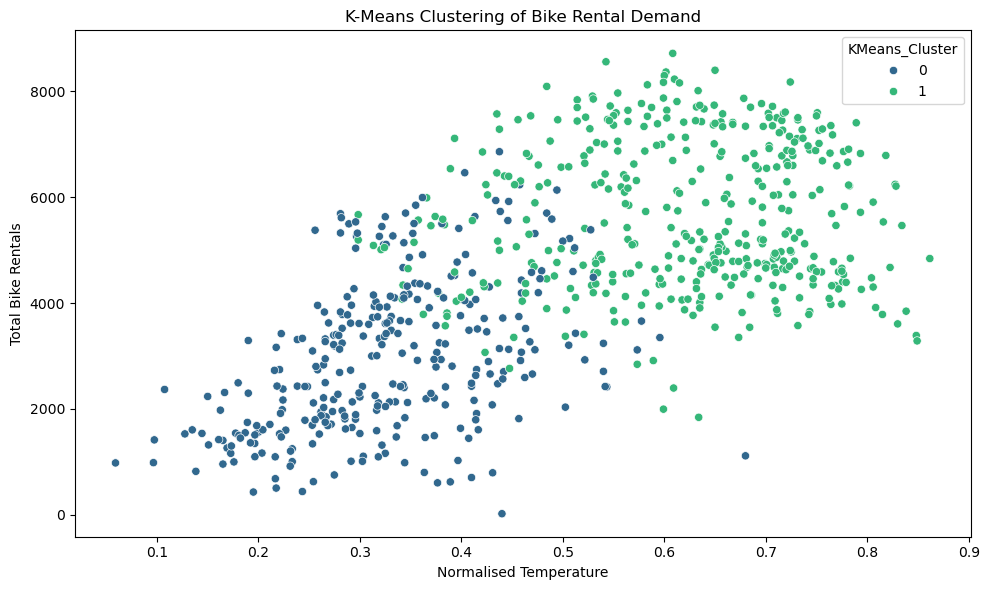

In [16]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="temp",
    y="cnt",
    hue="KMeans_Cluster",
    palette="viridis"
)

plt.title("K-Means Clustering of Bike Rental Demand")
plt.xlabel("Normalised Temperature")
plt.ylabel("Total Bike Rentals")
plt.tight_layout()
plt.show()

### 6.5 Agglomerative Clustering

In [17]:
from sklearn.cluster import AgglomerativeClustering

agg_model = AgglomerativeClustering(
    n_clusters=best_k
)

df["Agg_Cluster"] = agg_model.fit_predict(X_scaled)

print("Agglomerative Cluster Distribution:")
print(df["Agg_Cluster"].value_counts().sort_index())

Agglomerative Cluster Distribution:
Agg_Cluster
0    437
1    294
Name: count, dtype: int64


### Interpretation: Agglomerative Clustering

Agglomerative Clustering was applied to the same standardised dataset using two clusters.

The algorithm divided the 731 observations into two groups, containing 437 and 294 observations respectively.

Unlike K-Means, which uses cluster centres, Agglomerative Clustering combines observations based on their similarities.

The Silhouette Score was approximately 0.248, while the Davies–Bouldin Index was approximately 1.438.

These results suggest that Agglomerative Clustering produced less clearly separated groups than K-Means for this dataset and configuration.

### 6.6 Compare Both Clustering Algorithms

In [18]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

results = pd.DataFrame({
    "Algorithm": ["K-Means", "Agglomerative"],
    "Silhouette Score": [
        silhouette_score(X_scaled, df["KMeans_Cluster"]),
        silhouette_score(X_scaled, df["Agg_Cluster"])
    ],
    "Davies-Bouldin Index": [
        davies_bouldin_score(X_scaled, df["KMeans_Cluster"]),
        davies_bouldin_score(X_scaled, df["Agg_Cluster"])
    ]
})

results

,Algorithm,Silhouette Score,Davies-Bouldin Index
0,K-Means,0.301661,1.359205
1,Agglomerative,0.247848,1.438407


### Comparison of Clustering Algorithms

In this analysis, I compared K-Means and Agglomerative Clustering using the Silhouette Score and Davies–Bouldin Index.

K-Means achieved a Silhouette Score of 0.302 and a Davies–Bouldin Index of 1.359.

Agglomerative Clustering achieved a lower Silhouette Score of 0.248 and a higher Davies–Bouldin Index of 1.438.

A higher Silhouette Score indicates better cluster separation, while a lower Davies–Bouldin Index indicates more compact and separated clusters.

Based on these evaluation metrics, K-Means performed better than Agglomerative Clustering in this experiment.

However, the relatively low Silhouette Scores indicate that the clustering structure is not strongly separated. Further feature selection or alternative clustering settings may improve the results.

From a business perspective, these clusters could help identify different patterns of bike rental demand and support decisions about resource planning.

### 6.7 Cluster Profile Analysis

In [19]:
# Calculate average values for each cluster
cluster_profile = df.groupby("KMeans_Cluster")[
    ["temp", "hum", "windspeed", "cnt"]
].mean()

print("K-Means Cluster Profiles:")
display(cluster_profile.round(2))

K-Means Cluster Profiles:


,temp,hum,windspeed,cnt
KMeans_Cluster,,,,
0,0.33,0.59,0.22,2966.57
1,0.62,0.65,0.17,5655.84


### Interpretation: Cluster Profile Analysis

The K-Means clustering model identified two different groups of bike rental demand.

Cluster 0 contains 313 days, with an average of approximately 2,967 bike rentals per day. This cluster generally represents lower-demand days with cooler temperatures and higher windspeed.

Cluster 1 contains 418 days, with an average of approximately 5,656 bike rentals per day. This cluster represents higher-demand days, generally associated with warmer temperatures and lower windspeed.

The results suggest that weather conditions and rental activity differ between the two groups.

From a business perspective, these findings could help bike-sharing companies plan bicycle availability and manage resources during different demand conditions.

However, the clusters were created using rental counts as well as weather variables, so the demand differences are partly influenced by the features used in the clustering process.

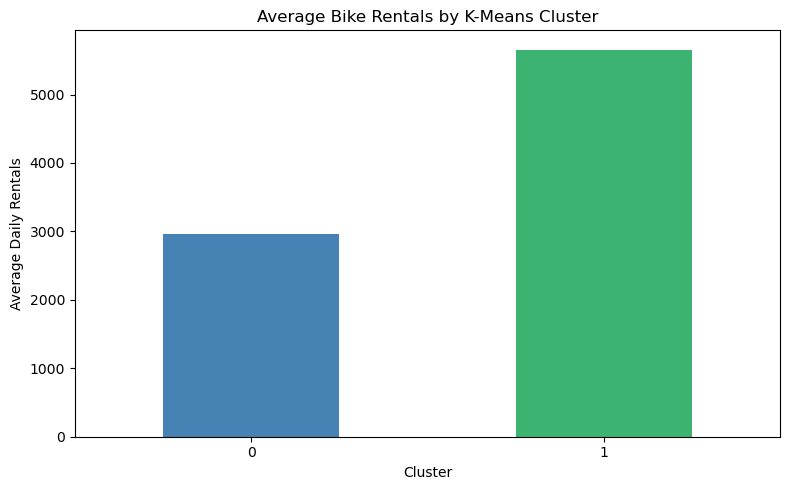

In [20]:
# Visualise average rentals by cluster
cluster_profile["cnt"].plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "mediumseagreen"]
)

plt.title("Average Bike Rentals by K-Means Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Daily Rentals")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Time Series Forecasting

### 7.1 Data Preparation

In this section, I use time series forecasting methods to analyse and predict daily bike rental demand.

The dataset contains daily bike rental records from January 2011 to December 2012.

I use the date column as the time index and the total rental count as the target variable.

The main objective is to investigate trends and seasonal patterns and evaluate how accurately ARIMA and SARIMA models can forecast bike rental demand.

In [21]:
# Prepare time series data
ts = df[["dteday", "cnt"]].copy()

# Convert date column
ts["dteday"] = pd.to_datetime(ts["dteday"])

# Sort by date
ts = ts.sort_values("dteday")

# Set date as index
ts = ts.set_index("dteday")

# Set daily frequency
ts = ts.asfreq("D")

# Check the dataset
print("Time Series Shape:", ts.shape)

print("Missing Values:")
print(ts.isnull().sum())

display(ts.head())

Time Series Shape: (731, 1)
Missing Values:
cnt    0
dtype: int64


,cnt
dteday,
2011-01-01,985
2011-01-02,801
2011-01-03,1349
2011-01-04,1562
2011-01-05,1600


## 7.2 Plot the Time Series

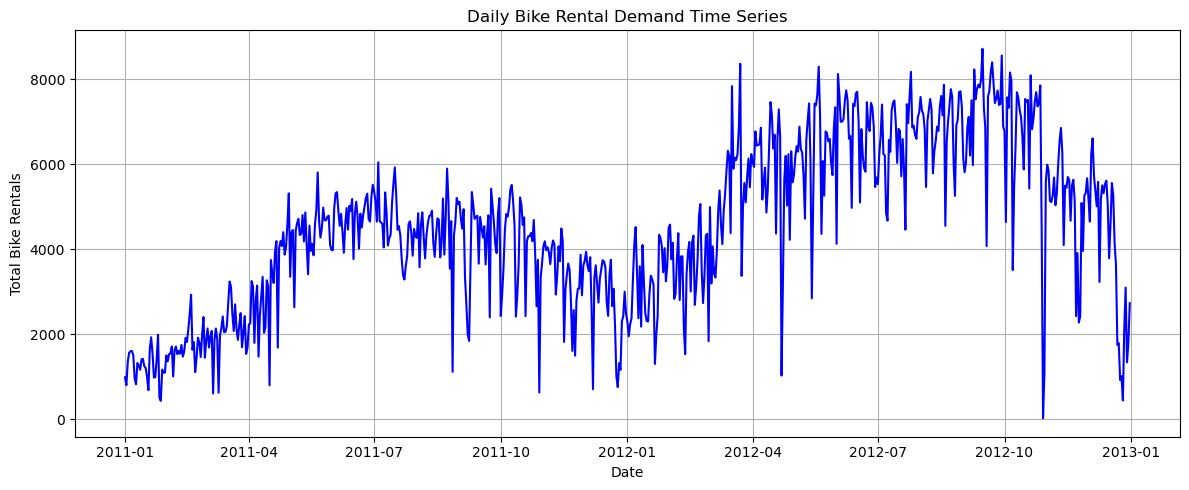

In [22]:
plt.figure(figsize=(12, 5))

plt.plot(
    ts.index,
    ts["cnt"],
    color="blue"
)

plt.title("Daily Bike Rental Demand Time Series")
plt.xlabel("Date")
plt.ylabel("Total Bike Rentals")

plt.grid(True)
plt.tight_layout()
plt.show()

## 7.3 Train/Test Split

In [23]:
# Split data into training and testing sets
train_size = int(len(ts) * 0.8)

train = ts["cnt"].iloc[:train_size]
test = ts["cnt"].iloc[train_size:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Training observations: 584
Testing observations: 147
Training period: 2011-01-01 00:00:00 to 2012-08-06 00:00:00
Testing period: 2012-08-07 00:00:00 to 2012-12-31 00:00:00


## 7.4 Visualise Train/Test Split

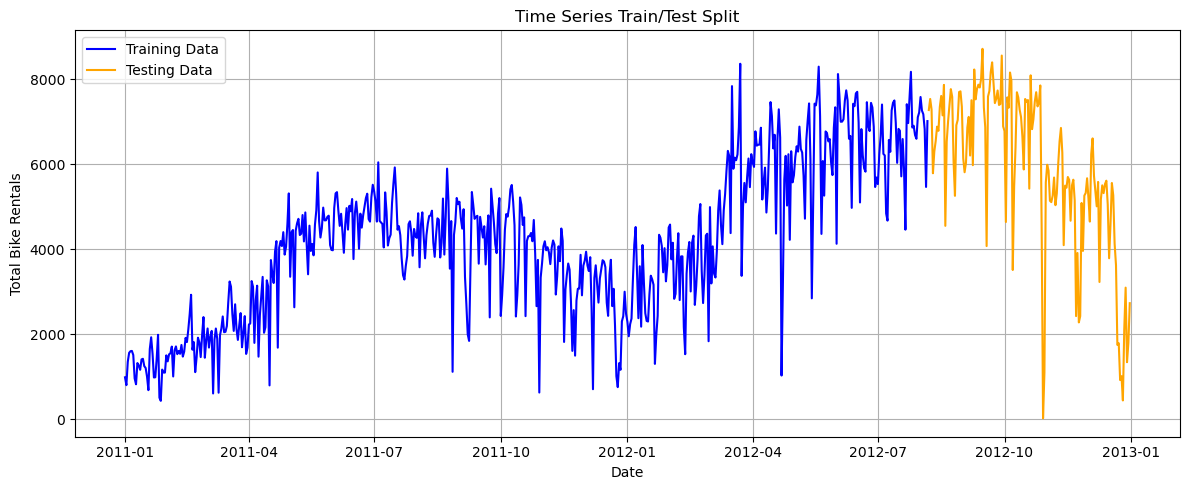

In [24]:
plt.figure(figsize=(12, 5))

plt.plot(
    train.index,
    train,
    label="Training Data",
    color="blue"
)

plt.plot(
    test.index,
    test,
    label="Testing Data",
    color="orange"
)

plt.title("Time Series Train/Test Split")
plt.xlabel("Date")
plt.ylabel("Total Bike Rentals")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Interpretation: Time Series Data and Train/Test Split

The time series dataset contains 731 daily observations from January 2011 to December 2012.

The line graph shows that bike rental demand generally increased between 2011 and 2012. It also shows noticeable fluctuations and possible seasonal patterns.

I divided the dataset into 80% training data and 20% testing data.

The training dataset contains 584 observations, while the testing dataset contains 147 observations.

I maintained the chronological order of the data because time series forecasting uses past observations to predict future values.

The training data will be used to develop the ARIMA and SARIMA models, while the testing data will be used to evaluate forecasting performance.

### 7.5 Stationarity Test (ADF Test)

Before developing the ARIMA model, I used the Augmented Dickey-Fuller (ADF) test to check whether the time series is stationary.

A stationary time series has statistical properties that remain relatively stable over time.

The ADF test helps determine whether differencing may be required before applying the ARIMA model.

The hypotheses are:

- H0: The time series has a unit root (non-stationary).
- H1: The time series does not have a unit root.

If the p-value is below 0.05, I reject the null hypothesis. Otherwise, I do not reject it.

In [25]:
from statsmodels.tsa.stattools import adfuller

# Perform ADF test on training data
adf_result = adfuller(train.dropna())

print("ADF Statistic:", adf_result[0])
print("P-value:", adf_result[1])
print("Critical Values:")

for key, value in adf_result[4].items():
    print(key, ":", value)

if adf_result[1] < 0.05:
    print("The training series appears stationary.")
else:
    print("The training series appears non-stationary.")

ADF Statistic: -1.5423292767923371
P-value: 0.5124775030347247
Critical Values:
1% : -3.4418139386911513
5% : -2.866597262008035
10% : -2.5694633721967906
The training series appears non-stationary.


### Interpretation: ADF Test

I performed the Augmented Dickey-Fuller (ADF) test to check whether the training time series was stationary.

The ADF statistic was approximately -1.5423, and the p-value was 0.5125.

Since the p-value was greater than 0.05, I could not reject the null hypothesis of a unit root.

This suggests that the original training series is non-stationary and may require differencing before applying an ARIMA model.

### 7.6 First Differencing
First differencing was applied to investigate whether the stationarity of the training series could be improved.

This method calculates the difference between consecutive daily rental observations.

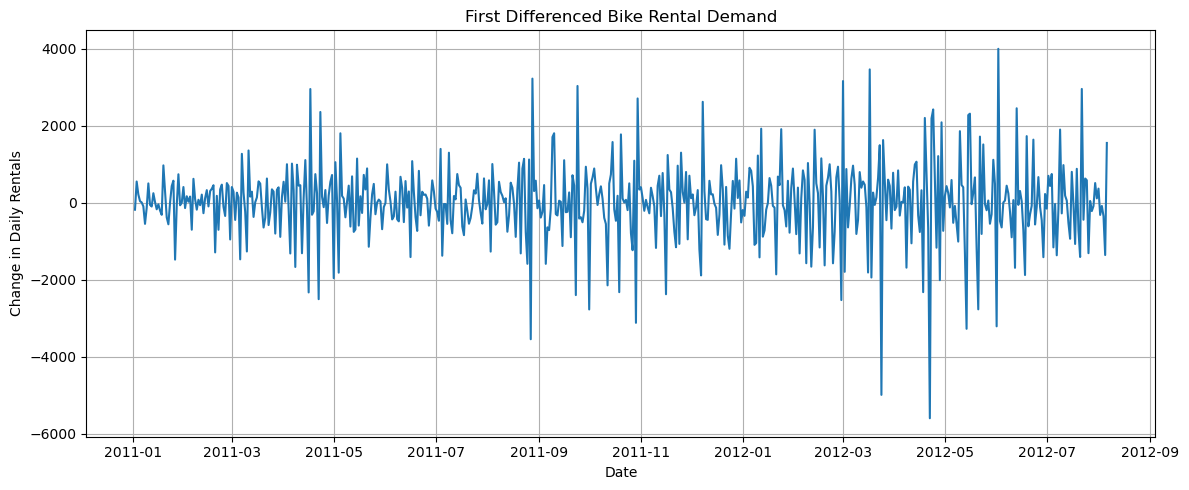

ADF Statistic: -10.541697444995206
P-value: 8.616831286941856e-19
Differenced series appears stationary.


In [26]:
# Apply first differencing to training data
train_diff = train.diff().dropna()

# Plot differenced time series
plt.figure(figsize=(12, 5))

plt.plot(train_diff.index, train_diff)

plt.title("First Differenced Bike Rental Demand")
plt.xlabel("Date")
plt.ylabel("Change in Daily Rentals")

plt.grid(True)
plt.tight_layout()
plt.show()

# ADF test after differencing
adf_diff = adfuller(train_diff)

print("ADF Statistic:", adf_diff[0])
print("P-value:", adf_diff[1])

if adf_diff[1] < 0.05:
    print("Differenced series appears stationary.")
else:
    print("Differenced series appears non-stationary.")

### Interpretation: First Differencing

I applied first differencing to the training dataset to reduce non-stationarity.

After differencing, the ADF statistic decreased to approximately -10.5417, and the p-value was extremely small (less than 0.001).

Since the p-value was below 0.05, I rejected the null hypothesis of a unit root.

The differenced series also fluctuates around zero, although some large changes remain.

Based on these results, I selected a differencing order of d = 1 as the initial choice for the ARIMA model.

### 7.7 ACF and PACF Analysis
I used the Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) to investigate the relationships between observations at different time lags.

The ACF plot helps identify possible moving average (q) components, while the PACF plot helps identify possible autoregressive (p) components.

These plots provide initial guidance for selecting ARIMA model parameters.

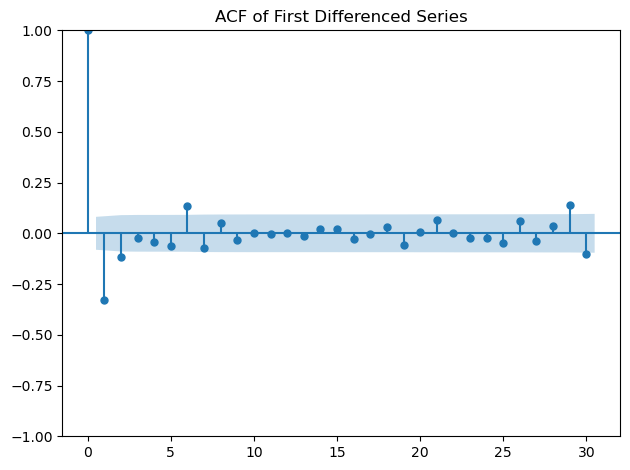

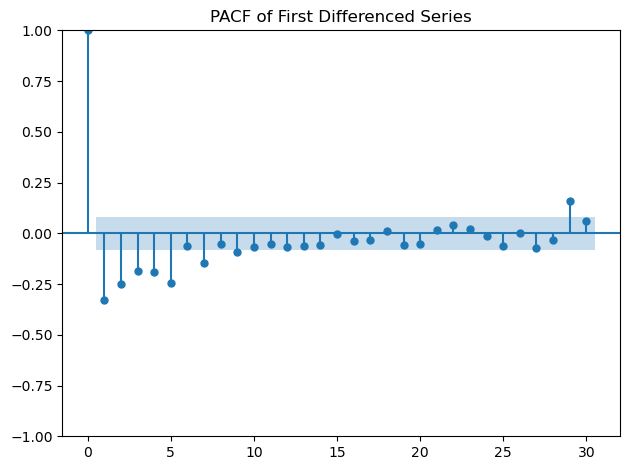

In [27]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# ACF plot
plot_acf(train_diff, lags=30)
plt.title("ACF of First Differenced Series")
plt.tight_layout()
plt.show()

# PACF plot
plot_pacf(train_diff, lags=30, method="ywm")
plt.title("PACF of First Differenced Series")
plt.tight_layout()
plt.show()

### Interpretation: ACF and PACF Analysis

The ACF plot shows a noticeable negative autocorrelation at lag 1, while most other correlations are relatively small.

The PACF plot shows several negative correlations at the earlier lags, suggesting that past observations may influence changes in daily bike rental demand.

Based on these patterns, I decided to test several ARIMA models with different autoregressive (p) and moving average (q) parameters.

The differencing order (d) was initially set to 1 based on the ADF test results.

I will compare candidate models using the Akaike Information Criterion (AIC) and residual diagnostics before selecting a suitable model.

### 7.8 ARIMA Model Selection

In this section, I compare different ARIMA models to identify suitable parameters for forecasting daily bike rental demand.

Based on the stationarity test, I initially selected a differencing order of d = 1.

I tested different combinations of autoregressive (p) and moving average (q) parameters.

The Akaike Information Criterion (AIC) was used to compare the candidate models. A lower AIC indicates a better balance between model fit and complexity among the fitted models.

The selected model will be evaluated further using residual diagnostics and forecasting performance.

In [29]:
import pandas as pd
import warnings
from statsmodels.tsa.arima.model import ARIMA

# Store ARIMA model results
arima_results = []

# Test different p and q values
for p in range(4):
    for q in range(4):

        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")

                model = ARIMA(
                    train,
                    order=(p, 1, q)
                )

                fitted_model = model.fit()

            arima_results.append({
                "p": p,
                "d": 1,
                "q": q,
                "AIC": fitted_model.aic
            })

        except Exception as e:
            print(f"ARIMA({p},1,{q}) failed: {e}")

# Create results table
arima_results_df = pd.DataFrame(arima_results)

# Sort by lowest AIC
arima_results_df = arima_results_df.sort_values(
    by="AIC"
).reset_index(drop=True)

display(arima_results_df.head(10))

,p,d,q,AIC
0,2,1,2,9519.477166
1,1,1,1,9520.562072
2,0,1,2,9520.567525
3,1,1,3,9520.843787
4,3,1,3,9521.269464
5,2,1,1,9521.450692
6,0,1,3,9521.562923
7,1,1,2,9522.324066
8,3,1,1,9522.385942
9,2,1,3,9522.773500


### Interpretation: ARIMA Model Selection

I compared different ARIMA models using the Akaike Information Criterion (AIC).

Among the tested models, ARIMA(2,1,2) achieved the lowest AIC value of approximately 9519.48.

The model uses two autoregressive terms, first-order differencing, and two moving average terms.

Although ARIMA(2,1,2) had the lowest AIC, some simpler models had similar values. Therefore, I will also consider residual diagnostics and forecasting performance before making the final model selection.

### 7.9 Select the Best ARIMA Model

In [30]:
# Select the model with the lowest AIC
best_model_row = arima_results_df.iloc[0]

best_p = int(best_model_row["p"])
best_d = int(best_model_row["d"])
best_q = int(best_model_row["q"])

best_order = (best_p, best_d, best_q)

print("Best ARIMA Order:", best_order)
print("Lowest AIC:", best_model_row["AIC"])

# Fit the selected ARIMA model
best_arima = ARIMA(
    train,
    order=best_order
)

best_arima_fit = best_arima.fit()

print(best_arima_fit.summary())

Best ARIMA Order: (2, 1, 2)
Lowest AIC: 9519.477166296243
                               SARIMAX Results                                
Dep. Variable:                    cnt   No. Observations:                  584
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -4754.739
Date:                Thu, 22 Oct 2026   AIC                           9519.477
Time:                        00:57:49   BIC                           9541.318
Sample:                    01-01-2011   HQIC                          9527.990
                         - 08-06-2012                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.1981      0.113     10.595      0.000       0.976       1.420
ar.L2         -0.3059      0.045     -6.837      0.000      -0.394      -

### Interpretation: ARIMA Model Summary

The selected ARIMA(2,1,2) model was fitted using 584 training observations.

The model achieved an AIC of 9519.48 and a BIC of 9541.32.

The Ljung–Box test at lag 1 produced a p-value of 0.92, suggesting no significant residual autocorrelation at that lag.

However, the Jarque–Bera and heteroskedasticity tests produced very small p-values, indicating that the residuals are not normally distributed and their variance may change over time.

These results suggest that the model captures some patterns in the data but has limitations that should be considered when evaluating its forecasts.

### 7.10 — Residual Diagnostics

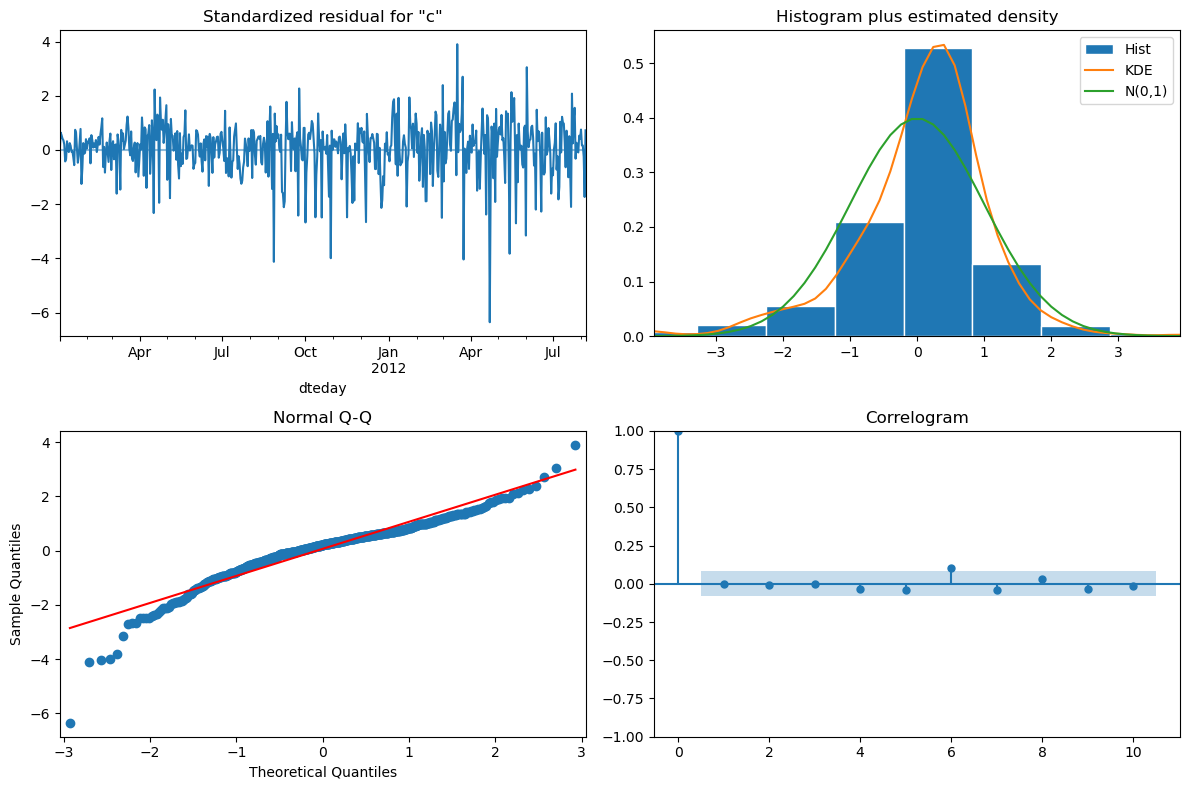

In [31]:
# Plot residual diagnostics
best_arima_fit.plot_diagnostics(
    figsize=(12, 8)
)

plt.tight_layout()
plt.show()

### Interpretation: Residual Diagnostics

I examined the residual diagnostic plots to evaluate the ARIMA(2,1,2) model.

The standardized residuals fluctuate around zero, although several large negative errors are visible.

The histogram and Q-Q plot suggest that the residuals do not follow a normal distribution, particularly in the tails.

The correlogram shows relatively small autocorrelations at most displayed lags, but there may still be some remaining dependence.

Therefore, I will use additional diagnostic tests and compare the model's forecasts against actual testing observations.

### 7.11 — Additional Ljung–Box Test
I used the Ljung–Box test to check whether the ARIMA residuals contain significant autocorrelation at multiple lags.

The null hypothesis is that there is no autocorrelation up to the selected lag.

A p-value below 0.05 suggests that significant autocorrelation may remain in the residuals.

In [32]:
from statsmodels.stats.diagnostic import acorr_ljungbox

lb_results = acorr_ljungbox(
    best_arima_fit.resid,
    lags=[7, 14, 21],
    return_df=True
)

display(lb_results)

,lb_stat,lb_pvalue
7,9.442947,0.222398
14,11.321298,0.660631
21,15.486255,0.797786


### Interpretation: Ljung–Box Test

I performed the Ljung–Box test to check for remaining autocorrelation in the ARIMA model residuals.

The p-values at lags 7, 14, and 21 were 0.2224, 0.6606, and 0.7978, respectively.

Since all p-values were greater than 0.05, I could not reject the null hypothesis of no autocorrelation up to these lags.

This suggests that the ARIMA model has captured much of the autocorrelation structure in the training data. However, this does not guarantee accurate forecasting performance.

### 7.12 ARIMA Forecasting

I used the fitted ARIMA(2,1,2) model to forecast bike rental demand for the 147-day testing period.

The forecast was generated using only the training data, and the predicted values were compared with the actual observations.

This evaluation helps determine how accurately the ARIMA model predicts unseen future demand.

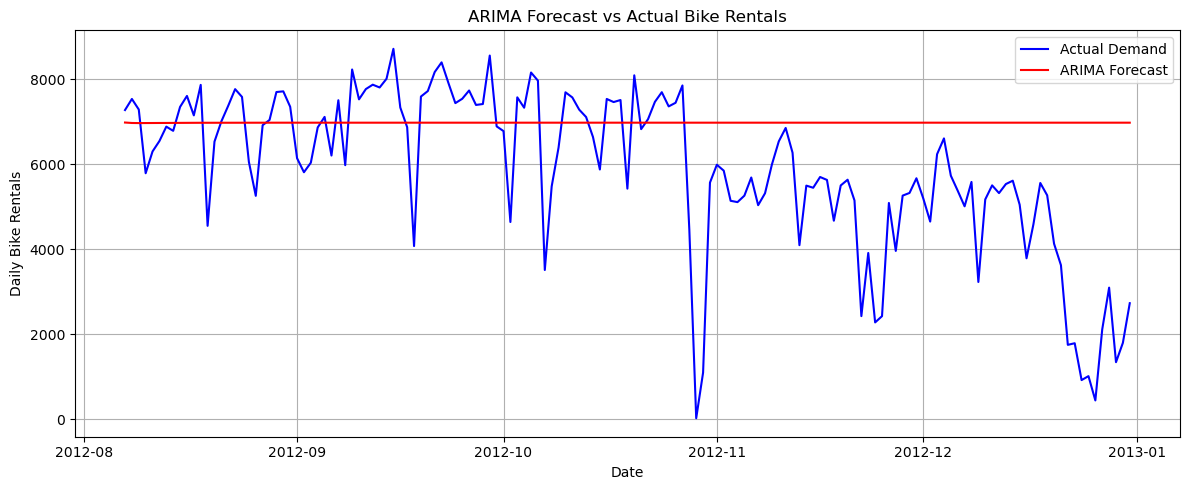

In [33]:
# Forecast the testing period
arima_forecast = best_arima_fit.forecast(
    steps=len(test)
)

# Match forecast dates with test dates
arima_forecast = pd.Series(
    arima_forecast.to_numpy(),
    index=test.index,
    name="ARIMA Forecast"
)

# Plot actual vs predicted values
plt.figure(figsize=(12, 5))

plt.plot(
    test.index,
    test,
    label="Actual Demand",
    color="blue"
)

plt.plot(
    arima_forecast.index,
    arima_forecast,
    label="ARIMA Forecast",
    color="red"
)

plt.title("ARIMA Forecast vs Actual Bike Rentals")
plt.xlabel("Date")
plt.ylabel("Daily Bike Rentals")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### 7.13 ARIMA Forecast Evaluation

I evaluated the ARIMA model using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Mean Absolute Percentage Error (MAPE).

MAE measures the average absolute difference between actual and predicted rental counts.

RMSE gives greater weight to large forecasting errors.

MAPE expresses forecasting error as a percentage, but it can be unreliable when actual observations are close to zero.

Lower error values generally indicate better forecasting performance.

In [34]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate MAE
arima_mae = mean_absolute_error(
    test,
    arima_forecast
)

# Calculate RMSE
arima_rmse = np.sqrt(
    mean_squared_error(test, arima_forecast)
)

# Calculate MAPE safely
actual = test.to_numpy()
predicted = arima_forecast.to_numpy()

nonzero = actual != 0

arima_mape = np.mean(
    np.abs(
        (actual[nonzero] - predicted[nonzero])
        / actual[nonzero]
    )
) * 100

print("ARIMA MAE:", round(arima_mae, 2))
print("ARIMA RMSE:", round(arima_rmse, 2))
print("ARIMA MAPE:", round(arima_mape, 2), "%")

ARIMA MAE: 1550.72
ARIMA RMSE: 2162.51
ARIMA MAPE: 272.56 %


### Interpretation: ARIMA Forecasting Performance

I evaluated the ARIMA(2,1,2) model using 147 testing observations.

The model produced an MAE of 1550.72, an RMSE of 2162.51, and a MAPE of 272.56%.

The forecast graph shows that the ARIMA predictions remain almost constant at approximately 7,000 rentals, while actual demand changes considerably throughout the testing period.

This indicates that the model struggles to capture changes in daily bike rental demand over a long forecasting horizon.

The very high MAPE may also be influenced by actual rental values close to zero.

Therefore, I will investigate whether a SARIMA model can improve forecasting accuracy by including seasonal patterns.

### 7.14 SARIMA Model Preparation

I will also investigate a Seasonal ARIMA (SARIMA) model to determine whether seasonal patterns improve forecasting accuracy.

Since the dataset contains daily observations, I will initially investigate a seven-day seasonal period to represent possible weekly patterns.

The SARIMA model includes both non-seasonal parameters (p,d,q) and seasonal parameters (P,D,Q,s).

The final model will be selected based on model diagnostics and forecasting performance.

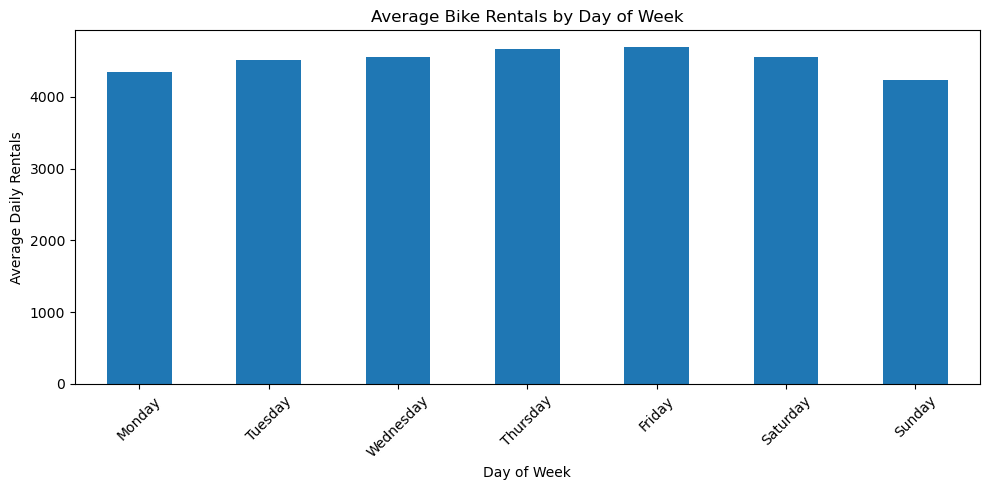

In [35]:
# Examine average demand by day of week
weekly_pattern = df.copy()

weekly_pattern["dteday"] = pd.to_datetime(
    weekly_pattern["dteday"]
)

weekly_pattern["day_name"] = weekly_pattern["dteday"].dt.day_name()

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekly_average = weekly_pattern.groupby(
    "day_name"
)["cnt"].mean().reindex(day_order)

plt.figure(figsize=(10, 5))

weekly_average.plot(kind="bar")

plt.title("Average Bike Rentals by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Daily Rentals")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Interpretation: Weekly Bike Rental Patterns

I analysed average bike rental demand across the seven days of the week.

The results show that Thursday and Friday have relatively higher average rental demand, while Sunday has the lowest average demand.

However, the differences between weekdays are not very large.

These findings suggest that weekly patterns may influence bike rental demand, although the strength of weekly seasonality requires further investigation.

I will initially test a seasonal period of seven days in the SARIMA model.

### 7.15 SARIMA Model Selection

In this section, I investigate Seasonal ARIMA (SARIMA) models to determine whether including weekly seasonal components improves the modelling of bike rental demand.

I selected a seasonal period of seven days as an initial candidate because the dataset contains daily observations.

I will compare several SARIMA parameter combinations using the Akaike Information Criterion (AIC).

A lower AIC indicates a better balance between model fit and complexity among the fitted candidate models.

The selected SARIMA model will then be evaluated using residual diagnostics and forecasting performance on the testing dataset.

In [37]:
import pandas as pd
import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Candidate non-seasonal parameters
orders = [
    (1, 1, 1),
    (2, 1, 1),
    (2, 1, 2)
]

# Candidate seasonal parameters
seasonal_orders = [
    (0, 0, 1, 7),
    (1, 0, 0, 7),
    (1, 0, 1, 7),
    (0, 1, 1, 7)
]

sarima_results = []

for order in orders:
    for seasonal_order in seasonal_orders:

        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")

                model = SARIMAX(
                    train,
                    order=order,
                    seasonal_order=seasonal_order,
                    enforce_stationarity=False,
                    enforce_invertibility=False
                )

                fitted = model.fit(
                    disp=False,
                    maxiter=200
                )

            if fitted.mle_retvals.get("converged", False):
                sarima_results.append({
                    "Order": order,
                    "Seasonal Order": seasonal_order,
                    "AIC": fitted.aic
                })
            else:
                print(
                    "Did not converge:",
                    order,
                    seasonal_order
                )

        except Exception as e:
            print(
                "Failed:",
                order,
                seasonal_order,
                str(e)
            )

sarima_results_df = pd.DataFrame(sarima_results)

if sarima_results_df.empty:
    print("No candidate models converged.")
else:
    sarima_results_df = sarima_results_df.sort_values(
        by="AIC"
    ).reset_index(drop=True)

    display(sarima_results_df)

,Order,Seasonal Order,AIC
0,"(2, 1, 2)","(0, 1, 1, 7)",9274.160032
1,"(1, 1, 1)","(0, 1, 1, 7)",9287.313515
2,"(2, 1, 1)","(0, 1, 1, 7)",9288.407323
3,"(2, 1, 2)","(0, 0, 1, 7)",9367.575588
4,"(2, 1, 2)","(1, 0, 1, 7)",9369.389330
5,"(2, 1, 1)","(1, 0, 0, 7)",9383.035432
6,"(2, 1, 1)","(0, 0, 1, 7)",9383.124392
7,"(2, 1, 2)","(1, 0, 0, 7)",9386.492320
8,"(1, 1, 1)","(0, 0, 1, 7)",9386.565552
9,"(1, 1, 1)","(1, 0, 1, 7)",9388.366208


### 7.16 Selected SARIMA Model

After comparing the candidate SARIMA models, I selected the converged model with the lowest AIC for further investigation.

I fitted the selected model using the training dataset.

The model summary provides information about the estimated parameters and model diagnostics.

I will evaluate the model's residuals and compare its forecasts against actual observations before deciding whether it performs better than ARIMA.

In [38]:
# Select best SARIMA candidate
best_sarima_row = sarima_results_df.iloc[0]

best_sarima_order = best_sarima_row["Order"]
best_seasonal_order = best_sarima_row["Seasonal Order"]

print("Best SARIMA Order:", best_sarima_order)
print("Best Seasonal Order:", best_seasonal_order)
print("Lowest AIC:", best_sarima_row["AIC"])

# Fit selected model
best_sarima = SARIMAX(
    train,
    order=best_sarima_order,
    seasonal_order=best_seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

best_sarima_fit = best_sarima.fit(
    disp=False,
    maxiter=200
)

print("Converged:", best_sarima_fit.mle_retvals["converged"])
print(best_sarima_fit.summary())

Best SARIMA Order: (2, 1, 2)
Best Seasonal Order: (0, 1, 1, 7)
Lowest AIC: 9274.160032177671
Converged: True
                                      SARIMAX Results                                      
Dep. Variable:                                 cnt   No. Observations:                  584
Model:             SARIMAX(2, 1, 2)x(0, 1, [1], 7)   Log Likelihood               -4631.080
Date:                             Thu, 22 Oct 2026   AIC                           9274.160
Time:                                     01:21:26   BIC                           9300.192
Sample:                                 01-01-2011   HQIC                          9284.320
                                      - 08-06-2012                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------

### Interpretation: SARIMA Model Selection

I tested 12 SARIMA parameter combinations using the training dataset.

The model SARIMA(2,1,2)(0,1,1,7) achieved the lowest AIC value of 9274.16 among the tested models.

The model converged successfully, and the Ljung–Box test at lag 1 produced a p-value of 0.82, indicating no significant residual autocorrelation at that lag.

However, the model summary also reported a near-singular covariance matrix, which suggests that some parameter estimates may be unstable.

Therefore, I will evaluate the residuals and forecasting accuracy before deciding whether the SARIMA model performs better than ARIMA.

### 7.17 SARIMA Residual Diagnostics

I examined the residuals of the selected SARIMA model to assess whether the model adequately captured the patterns in the training data.

Residual diagnostics help identify remaining autocorrelation, unusual observations and deviations from the assumptions of the model.

Ideally, residuals should fluctuate around zero without strong systematic patterns.

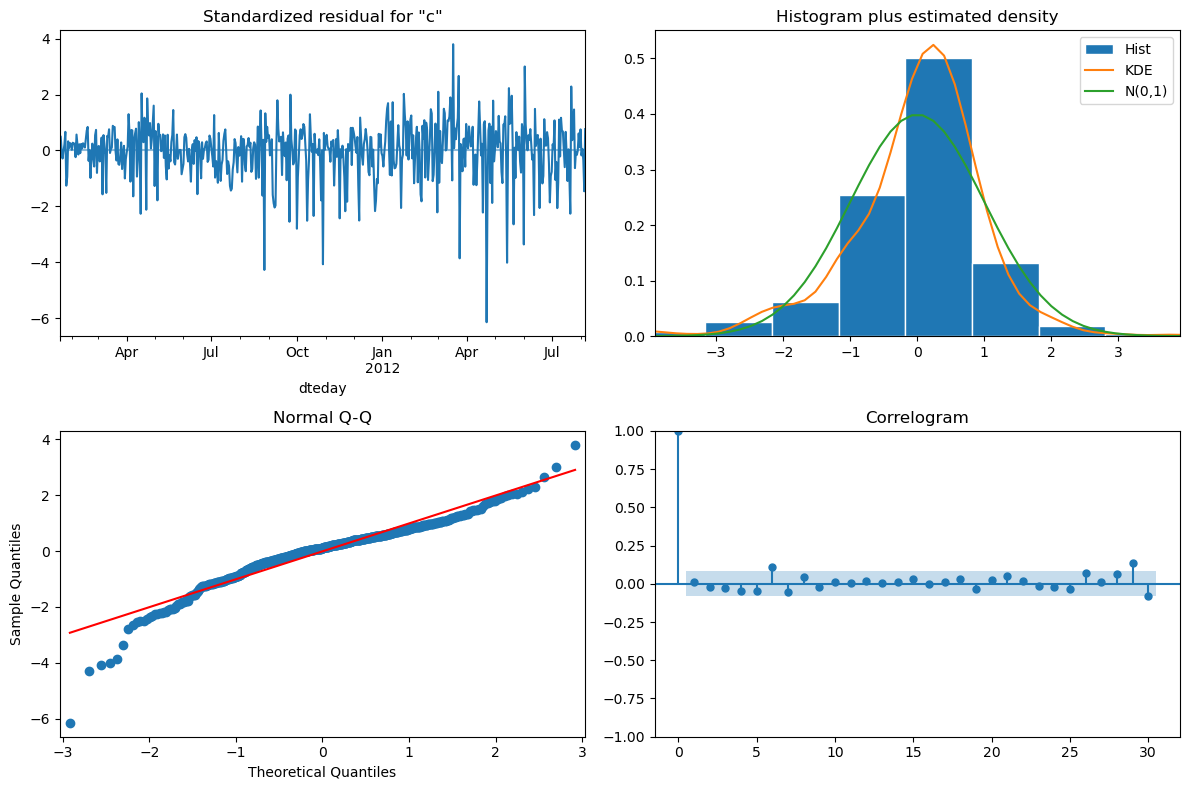

In [39]:
# SARIMA residual diagnostic plots
import matplotlib.pyplot as plt

best_sarima_fit.plot_diagnostics(
    figsize=(12, 8),
    lags=30
)

plt.tight_layout()
plt.show()

### Interpretation of SARIMA Residual Diagnostics

The residual diagnostic plots show that most residuals fluctuate around zero. However, some large positive and negative residuals are visible.

The histogram and Q-Q plot indicate that the residuals are not perfectly normally distributed, particularly at the tails.

The correlogram shows that most autocorrelation values are within the confidence intervals, suggesting that the model has captured much of the temporal dependence.

Overall, the SARIMA model captures some important patterns, but the residual distribution and unusual observations indicate certain limitations.

### 7.18 SARIMA Ljung–Box Test

I used the Ljung–Box test to check whether significant autocorrelation remains in the SARIMA model residuals.

The null hypothesis states that there is no autocorrelation up to the selected lag.

If the p-value is greater than 0.05, I do not reject the null hypothesis.

In [40]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Check residual autocorrelation
sarima_lb = acorr_ljungbox(
    best_sarima_fit.resid,
    lags=[7, 14, 21],
    return_df=True
)

display(sarima_lb)

,lb_stat,lb_pvalue
7,12.363857,0.089210
14,13.781537,0.466110
21,17.708893,0.667344


### Interpretation of the Ljung–Box Test

The Ljung–Box test was performed at lags 7, 14 and 21.

The p-values were 0.0892, 0.4661 and 0.6673 respectively.

Since all p-values are greater than 0.05, I failed to reject the null hypothesis at each selected lag.

This suggests that there is no statistically significant evidence of remaining autocorrelation at the tested lags. However, this does not guarantee that the model produces accurate forecasts.

### 7.19 SARIMA Forecasting

I used the fitted SARIMA model to forecast bike rental demand for the 147 observations in the testing dataset.

I compared the predicted values with actual daily bike rentals to assess the forecasting performance.

The graph helps show whether the model captures the changes and seasonal patterns in bike rental demand.

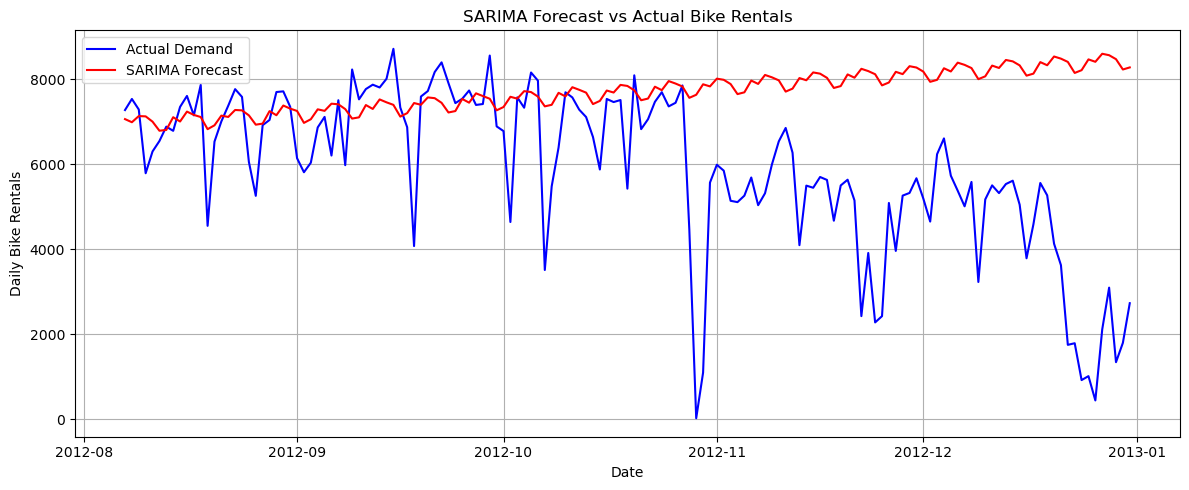

In [41]:
# Forecast SARIMA on test data
sarima_forecast = best_sarima_fit.get_forecast(
    steps=len(test)
).predicted_mean

# Match forecast dates with test dates
sarima_forecast.index = test.index

# Plot actual vs predicted values
plt.figure(figsize=(12, 5))

plt.plot(
    test.index,
    test,
    label="Actual Demand",
    color="blue"
)

plt.plot(
    sarima_forecast.index,
    sarima_forecast,
    label="SARIMA Forecast",
    color="red"
)

plt.title("SARIMA Forecast vs Actual Bike Rentals")
plt.xlabel("Date")
plt.ylabel("Daily Bike Rentals")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### 7.20 SARIMA Forecast Evaluation

I evaluated the SARIMA forecasting performance using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Mean Absolute Percentage Error (MAPE).

MAE measures the average absolute difference between actual and predicted rental counts.

RMSE gives greater weight to larger prediction errors.

MAPE expresses the average percentage error, although it can become unreliable when actual rental counts are close to zero.

Lower MAE and RMSE values indicate better forecasting accuracy.

In [43]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate MAE
sarima_mae = mean_absolute_error(
    test,
    sarima_forecast
)

# Calculate RMSE
sarima_rmse = np.sqrt(
    mean_squared_error(test, sarima_forecast)
)

# Calculate MAPE excluding zero actual values
actual = test.to_numpy()
predicted = sarima_forecast.to_numpy()

nonzero = actual != 0

sarima_mape = np.mean(
    np.abs(
        (actual[nonzero] - predicted[nonzero])
        / actual[nonzero]
    )
) * 100

print("SARIMA MAE:", round(sarima_mae, 2))
print("SARIMA RMSE:", round(sarima_rmse, 2))
print("SARIMA MAPE:", round(sarima_mape, 2), "%")

SARIMA MAE: 2007.49
SARIMA RMSE: 2822.66
SARIMA MAPE: 308.95 %


### 7.21 Comparison of ARIMA and SARIMA Models

In this section, I compare the forecasting performance of ARIMA and SARIMA models using the same testing dataset.

I use MAE, RMSE, and MAPE to compare their prediction errors.

The main objective is to identify which model provides more accurate forecasts of daily bike rental demand.

The model with lower MAE and RMSE will generally be preferred, while MAPE will be interpreted carefully because the dataset contains very low rental counts.

In [44]:
# Compare ARIMA and SARIMA results
comparison = pd.DataFrame({
    "Model": ["ARIMA", "SARIMA"],
    "MAE": [arima_mae, sarima_mae],
    "RMSE": [arima_rmse, sarima_rmse],
    "MAPE (%)": [arima_mape, sarima_mape]
})

display(comparison.round(2))

,Model,MAE,RMSE,MAPE (%)
0,ARIMA,1550.72,2162.51,272.56
1,SARIMA,2007.49,2822.66,308.95


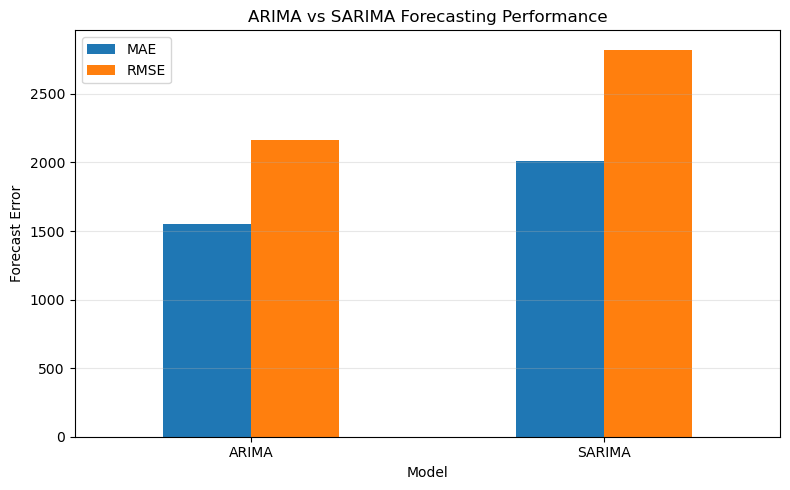

In [45]:
# Compare forecasting errors visually
comparison.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("ARIMA vs SARIMA Forecasting Performance")
plt.xlabel("Model")
plt.ylabel("Forecast Error")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 7.22 Final Model Comparison and Discussion

In this assessment, I applied ARIMA and SARIMA models to forecast daily bike rental demand using the Bike Sharing Dataset.

The dataset contained 731 daily observations from January 2011 to December 2012. I used 80% of the data for training and 20% for testing.

The selected ARIMA(2,1,2) model achieved an MAE of 1550.72 and an RMSE of 2162.51.

The selected SARIMA(2,1,2)(0,1,1,7) model achieved an MAE of 2007.49 and an RMSE of 2822.66.

Based on these results, ARIMA performed better than SARIMA because it produced lower forecasting errors on the testing dataset.

However, both models showed limitations. ARIMA produced relatively flat forecasts, while SARIMA predicted increasing demand even when actual bike rentals declined.

The MAPE values were also very high for both models, indicating substantial percentage forecasting errors. These values should be interpreted carefully because some actual rental counts were very close to zero.

Overall, ARIMA was the better-performing model among the two tested approaches, although neither model provided sufficiently accurate forecasts for reliable business planning.

Future improvements could include testing alternative model parameters, incorporating weather-related variables and evaluating models using rolling forecasts.

### 7.23 Conclusion

This assessment investigated bike rental demand using clustering and time series forecasting techniques.

For clustering, I applied K-Means and Agglomerative Clustering to identify different patterns in daily bike rental activity. K-Means achieved a higher Silhouette Score (0.3017) and a lower Davies–Bouldin Index (1.3592) than Agglomerative Clustering.

The clustering analysis identified two groups representing relatively lower and higher bike rental demand.

For time series forecasting, I developed ARIMA and SARIMA models to predict future bike rentals.

The evaluation results showed that ARIMA performed better than SARIMA on the testing dataset. However, both models had considerable forecasting errors.

These findings demonstrate how machine learning and time series techniques can support the analysis of bike rental demand, while also highlighting the importance of model evaluation and the limitations of forecasting.